<a href="https://colab.research.google.com/github/JuanitaRozo/Redes_Neuronales_III/blob/main/Practica2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Carga y Preparación de los Datos

En esta celda realizamos los siguientes pasos para preparar el conjunto de datos **Fashion MNIST**:

*   **Importación de librerías:** Cargamos numpy para operaciones numéricas, matplotlib para visualización y tensorflow para el modelado.
*   **Configuración de semillas (seed):** Establecemos una semilla aleatoria tanto en NumPy como en TensorFlow para asegurar que los resultados sean reproducibles en cada ejecución.
*   **Carga del dataset:** Descargamos e importamos las imágenes de entrenamiento y prueba de Fashion MNIST.
*   **Partición de validación:** Dividimos el conjunto de entrenamiento original para extraer un $10\%$ de datos de validación (x_dev, y_dev) usando un muestreo estratificado para mantener la proporción de las clases.
*   **Normalización:** Convertimos los píxeles de las imágenes (originalmente de 0 a 255) al rango $[0, 1]$ dividiendo por `255.0` para facilitar y acelerar la convergencia del entrenamiento.

In [ ]:
#cargo y vuelvo a preparar los datos


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

(x_total, y_total), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

x_train, x_dev, y_train, y_dev = train_test_split(
    x_total,
    y_total,
    test_size=0.10,
    random_state=42,
    stratify=y_total
)

x_train = x_train.astype("float32") / 255.0
x_dev = x_dev.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Entrenamiento:", x_train.shape)
print("Validación:", x_dev.shape)
print("Prueba:", x_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (54000, 28, 28)
Validación: (6000, 28, 28)
Prueba: (10000, 28, 28)


A partir de aqui creo la arquitectura de la red neuronal
para ello uso una red neuronal feedforward con una capa de entrada aplanada dos capas ocultas y diez salidas

La última capa utilizará softmax para generar las probabilidades de las diez clases

### 2. Definición de la Arquitectura del Modelo

Aquí definimos la estructura de nuestra red neuronal artificial mediante una función reutilizable:

*   **crear_modelo()**: Devuelve un modelo secuencial de Keras con:
    *   Una capa **Input** que define el tamaño de entrada de las imágenes ($28 \times 28$ píxeles).
    *   Una capa **Flatten** para aplanar la matriz bidimensional en un vector unidimensional de $784$ elementos.
    *   Dos capas densas (totalmente conectadas) ocultas de **128** y **64** neuronas con función de activación **ReLU**.
    *   Una capa de salida de **10** neuronas (una por clase) con activación **Softmax** para obtener una distribución de probabilidad sobre las categorías.
*   Finalmente, imprimimos un resumen del modelo (summary()) para inspeccionar el número de parámetros a entrenar.

In [ ]:

def crear_modelo():
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    return modelo

modelo_prueba = crear_modelo() #La función crear_modelo() nos permitirá crear modelos con la misma arquitectura y cambiar únicamente el optimizador
modelo_prueba.summary()




Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Entrenamiento y Comparativa de Optimizadores (SGD vs. Adam)

En esta sección realizamos un experimento comparativo entre dos optimizadores populares:

*   Definimos los optimizadores **SGD** (con un learning rate de $0.01$) y **Adam** (con un learning rate de $0.001$).
*   Iteramos sobre ellos para entrenar un modelo desde cero en cada caso (limpiando la sesión anterior con clear_session para evitar acumulación de memoria o pesos).
*   Compilamos el modelo utilizando la función de pérdida sparse_categorical_crossentropy (adecuada para etiquetas numéricas enteras) y la métrica de precisión (accuracy).
*   Entrenamos durante **10 épocas** con un tamaño de lote de $128$ y guardamos el historial del entrenamiento para su posterior análisis.

In [ ]:
#Comparamos SGD y Adam y tambien hago el entreno


resultados_opt = {}
historias = {}

optimizadores = {
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01),
    "Adam": tf.keras.optimizers.Adam(learning_rate=0.001)
}

for nombre, optimizador in optimizadores.items():
    print(f"\nEntrenando modelo con {nombre}...")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    modelo = crear_modelo()

    modelo.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    resultados_opt[nombre] = {
        "val_accuracy": max(historia.history["val_accuracy"]),
        "val_loss": min(historia.history["val_loss"])
    }

    historias[nombre] = historia.history

print("\nResultados de optimización:")
for nombre, valores in resultados_opt.items():
    print(
        nombre,
        "| Mejor val_accuracy:", round(valores["val_accuracy"], 4),
        "| Menor val_loss:", round(valores["val_loss"], 4)
    )



Entrenando modelo con SGD...
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6437 - loss: 1.1473 - val_accuracy: 0.7468 - val_loss: 0.7563
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7678 - loss: 0.6843 - val_accuracy: 0.7917 - val_loss: 0.6204
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7996 - loss: 0.5947 - val_accuracy: 0.8118 - val_loss: 0.5563
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8144 - loss: 0.5472 - val_accuracy: 0.8228 - val_loss: 0.5175
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8232 - loss: 0.5170 - val_accuracy: 0.8307 - val_loss: 0.4910
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8283 - loss: 0.4957 - val_accuracy: 0.8355 - val_loss: 0.4715
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8334 - loss: 0.4795 - val_accuracy: 0.8395 - val_loss: 0.4563
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8372 - l

### 4. Visualización de Resultados

Para concluir el análisis, graficamos las métricas obtenidas durante el entrenamiento con ambos optimizadores:

*   **Gráfico Izquierdo (Precisión de Validación):** Muestra cómo evoluciona el *accuracy* en el conjunto de validación época a época. Permite ver cuál optimizador alcanza mayor precisión.
*   **Gráfico Derecho (Pérdida de Validación):** Representa la evolución de la pérdida (*loss*) en el conjunto de validación. Nos ayuda a observar la velocidad de convergencia y si existe sobreajuste (overfitting).

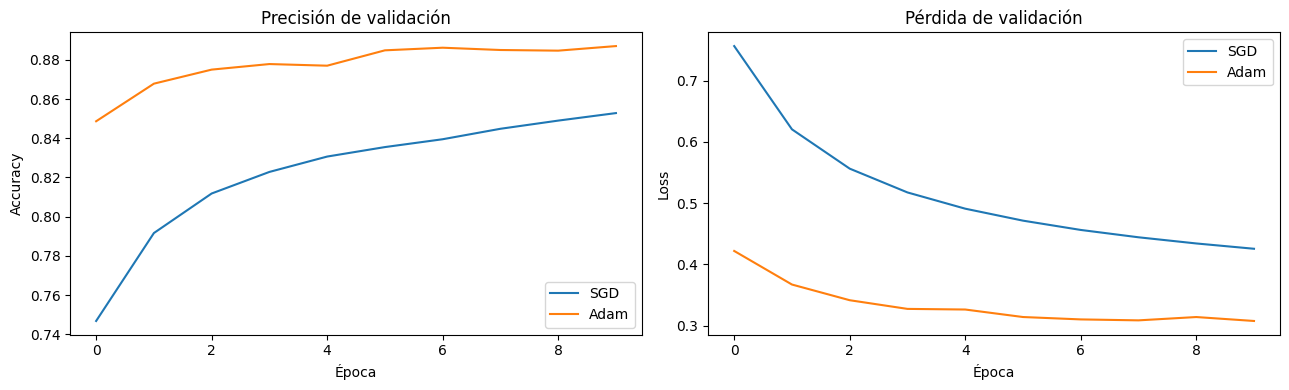

In [ ]:
#graficamos el entrenamiento


fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for nombre, h in historias.items():
    axes[0].plot(h["val_accuracy"], label=nombre)
    axes[1].plot(h["val_loss"], label=nombre)

axes[0].set_title("Precisión de validación")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Pérdida de validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()
